In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel(r"..\Telco_customer_churn.xlsx")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [5]:
df = df.drop(columns="Count",errors="ignore")

In [6]:
corr_matrix = df.select_dtypes([np.number]).corr()


In [13]:
corr_matrix["Churn Score"].abs()[corr_matrix["Churn Score"]<=0.2].sort_values(ascending=False).index.to_list()

['Tenure Months',
 'Monthly Charges',
 'CLTV',
 'Latitude',
 'Longitude',
 'Zip Code']

In [21]:
corr_matrix["Churn Value"].abs()[corr_matrix["Churn Value"]<=0.05].sort_values(ascending=False).index.to_list()

['Tenure Months', 'CLTV', 'Longitude', 'Latitude', 'Zip Code']

In [10]:
df.columns

Index(['CustomerID', 'Country', 'State', 'City', 'Zip Code', 'Lat Long',
       'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner',
       'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines',
       'Internet Service', 'Online Security', 'Online Backup',
       'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies',
       'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges',
       'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV',
       'Churn Reason'],
      dtype='str')

In [29]:
unwanted_cols = ["Phone Service","Streaming TV","Streaming Movies","CustomerID","Gender","Multiple Lines","Churn Reason","Tenure Months","CLTV"]

In [30]:
df1 = df.drop(columns=unwanted_cols, errors="raise")
# equivalent:
# df1 = df.drop(unwanted_cols, axis=1, errors="raise")

In [31]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country            7043 non-null   str    
 1   State              7043 non-null   str    
 2   City               7043 non-null   str    
 3   Zip Code           7043 non-null   int64  
 4   Lat Long           7043 non-null   str    
 5   Latitude           7043 non-null   float64
 6   Longitude          7043 non-null   float64
 7   Senior Citizen     7043 non-null   str    
 8   Partner            7043 non-null   str    
 9   Dependents         7043 non-null   str    
 10  Internet Service   7043 non-null   str    
 11  Online Security    7043 non-null   str    
 12  Online Backup      7043 non-null   str    
 13  Device Protection  7043 non-null   str    
 14  Tech Support       7043 non-null   str    
 15  Contract           7043 non-null   str    
 16  Paperless Billing  7043 non-null   

In [33]:
df1.columns.to_list()

['Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score']

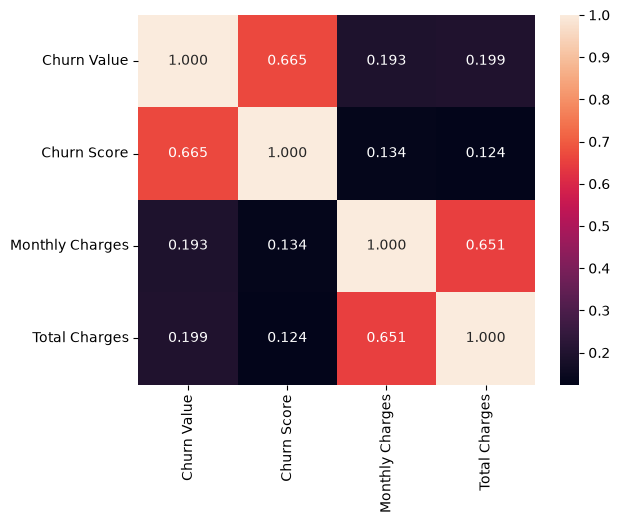

In [39]:
df1["Total Charges"] = pd.to_numeric(df1["Total Charges"],errors="coerce")
charges_features = ["Monthly Charges","Total Charges"]
required_features1 = ["Churn Value", "Churn Score"] + charges_features
corr_matrix = df1[required_features1].corr().abs()
plt.Figure(figsize=(10,8))
sns.heatmap(corr_matrix,annot=True,fmt=".3f")
plt.show()

In [42]:
charges_features

['Monthly Charges', 'Total Charges']

In [51]:
charges_df = df1[charges_features]
type(charges_df.values)

numpy.ndarray

In [56]:
r = charges_df["Monthly Charges"].corr(charges_df["Total Charges"])
r2 = r**(2)
vif = 1/(1-r2)
print(r)
vif

0.6510648032262027


np.float64(1.7357656997637443)

In [57]:
unwanted_cols2 = ["Zip Code","Lat Long"]
df1 = df1.drop(columns=unwanted_cols2,errors="ignore")

In [60]:
df1 = df1.drop(columns=["Churn Label"],errors="ignore")

In [115]:
y = df1[["Churn Value"]]
x = df1.drop(columns=["Churn Value","Churn Score"],errors="ignore")

In [116]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=10)

In [117]:
x_train.shape

(5634, 18)

In [118]:
x_train.columns

Index(['Country', 'State', 'City', 'Latitude', 'Longitude', 'Senior Citizen',
       'Partner', 'Dependents', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Contract',
       'Paperless Billing', 'Payment Method', 'Monthly Charges',
       'Total Charges'],
      dtype='str')

In [119]:
from imblearn.over_sampling import SMOTENC

In [120]:
y_train.columns

Index(['Churn Value'], dtype='str')

In [135]:
x_train.dtypes.value_counts

<bound method IndexOpsMixin.value_counts of Country                  str
State                    str
City                     str
Latitude             float64
Longitude            float64
Senior Citizen           str
Partner                  str
Dependents               str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges        float64
dtype: object>

In [138]:
smote = SMOTENC(
    categorical_features=[0,1,2,5,6,7,8,9,10,11,12,13,14,15],
    random_state=10
)


In [ ]:
# Check where NaNs are before resampling
print("NaN columns in x_train:", x_train.columns[x_train.isna().any()].tolist())
print("Total NaN in x_train:", x_train.isna().sum().sum())
print("Total NaN in y_train:", y_train.isna().sum().sum())

# Make copies so the original train sets remain unchanged
x_train_clean = x_train.copy()
y_train_clean = y_train.copy()

# Fill categorical/object NaNs
for col in x_train_clean.select_dtypes(include=["object", "category"]).columns:
    x_train_clean[col] = x_train_clean[col].fillna("Missing")

# Fill numeric NaNs with median
for col in x_train_clean.select_dtypes(include=["number"]).columns:
    x_train_clean[col] = x_train_clean[col].fillna(x_train_clean[col].median())

# Drop NaN targets if any
y_train_clean = y_train_clean.dropna()

# Align x and y after dropping rows in y
x_train_clean = x_train_clean.loc[y_train_clean.index]

# Final validation
assert not x_train_clean.isna().any().any()
assert not y_train_clean.isna().any().any()

x_train_balanced, y_train_balanced = smote.fit_resample(x_train_clean, y_train_clean)

ValueError: Input contains NaN.

In [64]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [98]:
ohe_features = ["Senior Citizen","Partner","Dependents","Internet Service","Online Security","Online Backup","Device Protection","Tech Support","Contract","Paperless Billing","Payment Method","Country","City","State"]

In [141]:
len(ohe_features)

14

In [103]:
preprocessor = ColumnTransformer(
    [("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False),ohe_features)],
    remainder="passthrough"
)

In [104]:
x_train_preprocessed = pd.DataFrame(
    preprocessor.fit_transform(x_train),
    columns=preprocessor.get_feature_names_out(),
    index=x_train.index
)